[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adrianfelipe812/prueba-conecta/blob/main/solucion.ipynb)

# Conecta+ · ¿A quién contactar y por qué se van? — Solución

**Prueba técnica Científico de Datos Senior.** "Hoy" = 31-dic-2025. Horizonte: 90 días.

| Pregunta | Respuesta corta (detalle abajo) |
|---|---|
| ¿A quién contactar? | Ensamble calibrado (logística L1 + Random Forest) + regla de **valor esperado** por plan → `predicciones.csv` |
| ¿Por qué se van? | Caída de uso de la app, **fallos de la versión 5.4.0 en Android**, solicitudes de cancelación y problemas de facturación |
| Hallazgo para la gerencia | La actualización Android 5.4.0 (1-ago-2025) triplica el churn de quienes la usan |

**Cómo ejecutar en Colab:** sube `datos_conecta.zip` al panel de archivos (o déjalo en Drive y ajusta la ruta)
y ejecuta *Entorno de ejecución → Ejecutar todo*. Tarda ~5 minutos. El código está en el paquete `conecta/` del
repositorio (bronze → silver → gold, NLP, modelos, negocio); este notebook lo orquesta y muestra las decisiones.

**Índice**
0. Entorno y datos · 1. Calidad e integración (medallion) · 2. Texto y logs (NLP) · 3. Modelo de churn ·
4. MLflow · 5. Decisión de negocio y `predicciones.csv` · 6. Hallazgo abierto · 7. Producción · 8. Limitaciones

## 0. Entorno y datos

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/adrianfelipe812/prueba-conecta.git"
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    RAIZ = Path("/content/repo")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(RAIZ)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(RAIZ / "requirements.txt")], check=True)
else:
    RAIZ = Path.cwd() if (Path.cwd() / "conecta").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)
print("Repositorio:", RAIZ.name, "| Colab:", EN_COLAB)

Repositorio: repo | Colab: True


In [2]:
import zipfile
from conecta import config

def extraer_seguro(zip_path: Path, destino: Path):
    """Descomprime validando rutas (sin rutas absolutas ni '..') y tamaño total razonable."""
    with zipfile.ZipFile(zip_path) as z:
        total = 0
        for info in z.infolist():
            nombre = info.filename.replace("\\", "/")
            if nombre.startswith("/") or ".." in Path(nombre).parts or ":" in nombre:
                raise ValueError(f"Ruta insegura en el zip: {nombre}")
            total += info.file_size
        if total > 2 * 1024**3:
            raise ValueError("El zip descomprimido supera 2 GB")
        destino.mkdir(parents=True, exist_ok=True)
        z.extractall(destino)

if EN_COLAB:
    ZIP = Path("/content/datos_conecta.zip")
    # Opción B (Drive): from google.colab import drive; drive.mount('/content/drive')
    # ZIP = Path("/content/drive/MyDrive/<ruta>/datos_conecta.zip")
    if not (config.DATA_DIR / "conecta.db").exists():
        assert ZIP.exists(), "Sube datos_conecta.zip al panel de archivos de Colab (o usa la opción Drive)"
        extraer_seguro(ZIP, config.DATA_DIR)
DATA_DIR, LAKE = config.DATA_DIR, config.LAKE_DIR
print("Datos:", sorted(p.name for p in DATA_DIR.iterdir()))

Datos: ['conecta.db', 'eventos.jsonl.gz', 'tickets.jsonl']


In [3]:
import warnings, logging
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"; os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from conecta import pipeline, io, gold, nlp, nlp_validacion, modelado as m, negocio, experimento_cortes
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
AZUL, NARANJA, TINTA, TENUE = "#2a78d6", "#eb6834", "#2b2b2b", "#8a8a86"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": TENUE, "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "xtick.color": TENUE, "ytick.color": TENUE,
                     "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
print("pandas", pd.__version__, "· numpy", np.__version__)

pandas 2.2.3 · numpy 2.4.6


## 1. Entender y preparar los datos (arquitectura medallion)

| Capa | Contenido | Regla |
|---|---|---|
| **Bronze** | Copia fiel de las 7 fuentes + metadatos de ingesta (fila, fuente, SHA-256, fecha) | No se corrige nada |
| **Silver** | Entidades limpias, tipadas, deduplicadas, en hora local Bogotá, tickets unificados + NLP | Toda corrección deja bandera u original |
| **Gold** | Una fila por cliente × fecha de corte con 46 variables calculadas **al corte** | Sin información del futuro |

El reporte de calidad **mide** cada problema en bronze y **verifica** en silver que quedó resuelto; el pipeline
se detiene si algún check falla.

In [4]:
reporte = pipeline.run(data_dir=DATA_DIR, lake_dir=LAKE)
reporte[reporte.capa == "bronze"][["tabla", "codigo", "regla", "n_afectados", "pct", "severidad", "accion"]]

[bronze] 7 tablas  (2.9s)
[silver] 7 tablas  (10.8s)
[gold] 2 tablas  (17.1s)
[calidad] 42 checks · 0 fallas


,tabla,codigo,regla,n_afectados,pct,severidad,accion
0,clientes,P01,ciudad escrita con variantes (17 valores para 6 ciudades),2000,66.67,media,Normalizar a nombre canónico
1,clientes,P02,"edad fuera de [18,90] (centinelas 0/99/999)",85,2.83,media,Reemplazar por NaN + flag
2,clientes,P03,contacto de retención anterior a la fecha de alta,76,2.53,baja,Marcar flag; no usar esa fecha
3,clientes,P04,estado_actual refleja HOY (fuga para cortes pasados),3000,100.00,alta,Excluir de features
4,suscripciones,P05,suscripciones cerradas por cambio de plan (no son churn),372,11.03,alta,Churn = fin de la ÚLTIMA suscripción
5,facturas,P06,"factura_id duplicado (recarga día 5, 07:00)",779,2.23,alta,"Deduplicar, conservar primera carga"
6,facturas,P07,facturas sin fecha_pago (pago se actualiza sin fecha de carga),1457,4.18,alta,Pago conocido solo si fecha_pago <= corte
7,facturas,P08,monto del Básico = 19.900 (precio anterior a abr-2025),5784,16.58,info,No es error: subida de precio (hallazgo)
8,tickets,P09,dos esquemas JSON distintos (3 combinaciones de claves),2468,52.76,alta,Unificar A y B en un esquema
9,tickets,P10,ID de cliente con formato texto 'CL-0xxxxx' (esquema A),2210,47.24,alta,Convertir a entero


In [5]:
print("Verificación en silver:", reporte[reporte.capa == "silver"].estado.value_counts().to_dict())
tablas = ["clientes", "suscripciones", "facturas", "tickets", "eventos", "etiquetas_entrenamiento", "clientes_a_puntuar"]
pd.DataFrame({"bronze": [len(io.read(LAKE, "bronze", t)) for t in tablas],
              "silver": [len(io.read(LAKE, "silver", t)) for t in tablas]}, index=tablas).assign(
    eliminadas=lambda d: d.bronze - d.silver)

Verificación en silver: {'ok': 26, 'info': 2}


,bronze,silver,eliminadas
clientes,3000,3000,0
suscripciones,3372,3372,0
facturas,34877,34098,779
tickets,4678,4678,0
eventos,104752,103289,1463
etiquetas_entrenamiento,4810,4810,0
clientes_a_puntuar,1558,1558,0


### Problemas principales y cómo se resolvieron
| Código | Problema | Tratamiento |
|---|---|---|
| P09 · P10 · P12 | `tickets.jsonl` mezcla **dos esquemas** (plataforma antigua en inglés/UTC hasta el 10-jun-2025, nueva en español, anidada, -05:00); ID `"CL-010792"` vs entero | Unificación a un esquema, ID entero (100 % de match con el CRM), todo a hora de Bogotá (en UTC aparecían 6 tickets "de 2026") |
| P06 | 779 facturas cargadas dos veces (recarga del día 5) | Deduplicar conservando la primera carga |
| P13 | 1.463 eventos de app duplicados | Eliminados |
| P01 · P02 | 17 escrituras de 6 ciudades; edades 0/99/999 | Ciudad canónica; edad → NaN + bandera |
| P03 | 76 contactos de retención anteriores al alta | Bandera; no cuentan como contacto |
| P05 | Un cambio de plan cierra una suscripción pero **no es churn** | Churn = termina la **última** suscripción en (corte, corte+90d]: reproduce 4.810/4.810 etiquetas |
| P04 · P07 | **Fugas**: `estado_actual` es la foto de hoy; `fecha_pago` se actualiza sin fecha de carga | Excluidas / pago conocido solo si `fecha_pago ≤ corte` |
| P08 | El Básico se cobra 19.900 hasta mar-2025 y 23.900 desde abr-2025 | No es error: subida de precio (+20 %) |
| P15 | Sarcasmo en tickets (p. ej., un cliente que "agradece" el servicio mientras reclama un cobro doble repetido) | NLP con detección de sarcasmo (sección 2) |

**Supuestos sobre campos** (no hay diccionario completo): fechas de corte inclusivas en hora local; "mensualidad actual" =
precio vigente del plan activo; `contactado_por_retencion` es reactivo (ocurre 3–19 días antes de irse);
la población de cada corte son todos los clientes con suscripción activa (verificado 3/3); eventos solo cubren 2025.
Catálogo completo en `docs/calidad_datos.md`.

## 2. Datos no estructurados: texto de tickets y logs de uso

**Texto.** Solo hay **38 textos distintos** de cliente (plantillas) y 3 respuestas genéricas de agente. Con tan poca
variedad no se justifica entrenar un clasificador ni pagar un LLM; se eligieron **reglas transparentes sobre léxicos
genéricos** (`conecta/nlp.py`): sarcasmo = elogio o risa + evento negativo del servicio, sin señal de "resuelto";
además intención (cancelar / amenaza de irse / bajar o subir de plan / soporte), frustración 0–2, recurrencia y tema precio.

In [6]:
tk = io.read(LAKE, "silver", "tickets")
print(f"Tickets: {len(tk)} · sarcásticos: {tk.nlp_sarcasmo.sum()} ({tk.nlp_sarcasmo.mean():.0%})")
# Confidencialidad: resumen por categoría, sin textos de clientes
resumen = tk.groupby("categoria").agg(tickets=("ticket_id", "size"), sarcasticos=("nlp_sarcasmo", "sum"),
                                      leidos_positivos_por_lexico=("nlp_sentimiento_lexico", lambda s: (s == "positivo").sum()))
resumen["pct_sarcasmo"] = (resumen.sarcasticos / resumen.tickets).round(3)
resumen.sort_values("sarcasticos", ascending=False)

Tickets: 4678 · sarcásticos: 974 (21%)


,tickets,sarcasticos,leidos_positivos_por_lexico,pct_sarcasmo
categoria,,,,
app_se_cierra,1071,359,359,0.335
cobro_doble,655,204,204,0.311
lentitud,829,149,149,0.180
cancelar,730,104,104,0.142
cambio_clave,663,104,104,0.157
no_reconoce_cobro,406,54,54,0.133
cambio_plan,324,0,0,0.000


In [7]:
ref = nlp_validacion.referencia(LAKE)
dev = nlp_validacion.robustez()
te = pd.read_csv(RAIZ / "conecta/recursos/prueba_nlp.csv")
te = te.join(pd.DataFrame([nlp.analizar(x) for x in te.texto]).add_prefix("pred_"))
val = pd.concat([nlp_validacion.metricas(ref, ["sarcasmo", "sentimiento", "intencion"]).assign(set="38 textos reales (etiqueta manual)"),
                 nlp_validacion.metricas(te, ["sarcasmo", "sentimiento", "intencion"]).assign(set="24 frases nuevas nunca usadas")])
val.pivot(index="campo", columns="set", values="exactitud").round(3)

set,24 frases nuevas nunca usadas,38 textos reales (etiqueta manual)
campo,,
intencion,0.958,1.000
sarcasmo,0.792,1.000
sentimiento,0.792,0.895


**Validación y límites.** En los textos reales las reglas son exactas en sarcasmo e intención; con frases nuevas el
sarcasmo baja a ~79 %, que es el límite honesto del método (elogios no listados, negaciones). Como contraste se probó
un modelo preentrenado en español (pysentimiento/RoBERTuito): detecta ironía en solo 5 de los 9 textos sarcásticos
reales, los clasifica como "positivos" y rinde peor que las reglas en los tres sets (detalle en `notebooks/02_nlp_tickets.ipynb`).
En producción: ampliar el léxico con tickets nuevos etiquetados y vigilar la tasa de textos fuera del set de referencia (check P15).

In [8]:
su = io.read(LAKE, "silver", "suscripciones")
fin = su[su.fin_es_churn].groupby("cliente_id").fecha_fin.max()
t = tk.merge(fin.rename("fecha_churn").reset_index(), on="cliente_id", how="left")
t = t[t.creado_en <= pd.Timestamp("2025-10-02")]
d = (t.fecha_churn - t.creado_en.dt.normalize()).dt.days
t["churn_90d_post"] = ((d >= 0) & (d <= 90)).astype(int)
print(f"Churn en los 90 días siguientes al ticket (base {t.churn_90d_post.mean():.0%}):")
display(t.groupby("nlp_intencion").churn_90d_post.agg(tickets="size", tasa_churn="mean").round(3).sort_values("tasa_churn"))
x = t[t.categoria != "cancelar"].groupby(["categoria", "nlp_sarcasmo"]).churn_90d_post.mean().unstack().round(3)
x.columns = ["sin sarcasmo", "con sarcasmo"]; x

Churn en los 90 días siguientes al ticket (base 30%):


,tickets,tasa_churn
nlp_intencion,,
bajar_plan,154,0.084
subir_plan,73,0.096
soporte,2502,0.171
amenaza_irse,169,0.213
cancelar,572,1.000


,sin sarcasmo,con sarcasmo
categoria,,
app_se_cierra,0.242,0.299
cambio_clave,0.111,0.122
cambio_plan,0.091,NaN
cobro_doble,0.238,0.288
lentitud,0.128,0.139
no_reconoce_cobro,0.132,0.146


La **intención** es la señal más útil (quien pide cancelar se va en 1–14 días; pedir bajar de plan tiene churn bajo:
oportunidad, no pérdida). El sarcasmo suma una señal pequeña y consistente dentro de cada categoría; su mayor valor
es no leer como satisfechos a clientes molestos. El sentimiento solo **engaña** (las cancelaciones corteses son "neutras").

**Logs de uso** (`eventos.jsonl.gz`, solo 2025): se convierten en variables al corte — logins y uso en 30 días,
tendencia frente a los 60 días previos, cierres `CRASH_ON_START`, errores, días sin actividad y uso de la versión 5.4.0.

## 3. Modelo de cancelación a 90 días

**Diseño de validación.** Las etiquetas existen para 3 cortes (mar, jun, sep 2025) y la tasa de churn **sube**
(10,3 % → 13,8 % → 15,7 %). Se valida **en el tiempo con origen móvil**: entrenar marzo → validar junio y entrenar
marzo+junio → validar septiembre. Un cliente aparece en varios cortes, por eso la calibración usa GroupKFold por cliente.

**Métricas.** El criterio de selección es el **valor neto de la decisión** (sección 5) medido con lo que realmente pasó,
expresado como % del máximo posible. AUC/PR-AUC miden el ordenamiento; Brier y log-loss la calibración, indispensable
porque la regla usa la probabilidad directamente.

**Features** (`docs/features.md`): perfil, contrato, facturación conocida al corte, tickets + NLP y uso de la app;
todas calculadas al corte con la misma función para entrenar y para puntuar.

In [9]:
F = io.read(LAKE, "gold", "features"); F["fecha_corte"] = pd.to_datetime(F["fecha_corte"])
F.groupby(["fecha_corte", "conjunto"]).agg(clientes=("cliente_id", "size"), tasa_churn=("churn_90d", "mean")).round(3)

,,clientes,tasa_churn
fecha_corte,conjunto,,
2025-03-31,entrenamiento,1447,0.103
2025-06-30,entrenamiento,1620,0.138
2025-09-30,entrenamiento,1743,0.157
2025-12-31,puntuar,1558,<NA>


In [10]:
resultados = m.comparar(LAKE)            # 15 candidatos × 2 pliegues (~1 min)
res, preds, mods = resultados
rk = m.ranking(res)
rk[rk.version == "calibrada"].drop(columns="version").round(4)

,modelo,pct_max_prom,pct_max_min,valor_neto_prom,roc_auc_prom,pr_auc_prom,brier_prom,pct_max_2025-06-30,pct_max_2025-09-30
2,02_logistica_l1,0.3438,0.2909,13741640.0,0.7174,0.3777,0.1121,0.2909,0.3967
3,01_logistica,0.3431,0.2705,13797000.0,0.6993,0.3603,0.1138,0.2705,0.4157
4,04_random_forest,0.3395,0.2478,13735420.0,0.7150,0.3180,0.1167,0.2478,0.4312
8,13_logistica_peso_valor,0.3268,0.2439,13199900.0,0.6845,0.3346,0.1176,0.2439,0.4098
9,12_ensamble_log_rf_lgbm,0.3256,0.2259,13222880.0,0.7142,0.3482,0.1144,0.2259,0.4254
11,05_extra_trees,0.3207,0.2383,12957420.0,0.7062,0.3307,0.1162,0.2383,0.4032
13,14_lightgbm_peso_valor,0.3035,0.2198,12285340.0,0.6750,0.2863,0.1197,0.2198,0.3872
15,06_hist_gradient_boosting,0.2977,0.2117,12066400.0,0.6669,0.2838,0.1199,0.2117,0.3837
17,08_knn,0.2927,0.2442,11714740.0,0.6653,0.2738,0.1207,0.2442,0.3413
18,03_arbol_decision,0.2863,0.2136,11563540.0,0.6738,0.2421,0.1223,0.2136,0.3590


In [11]:
r9 = res[(res.valida == "2025-09-30") & (res.version == "calibrada")].iloc[0]
print(f"Referencias en septiembre: máximo posible {r9.valor_maximo_oraculo/1e6:.1f} M COP · contactar a todos {r9.valor_contactar_todos/1e6:.1f} M COP")
top = ["02_logistica_l1", "04_random_forest", "01_logistica"]
for _, cva in m.PLIEGUES:
    va_ = F[F.fecha_corte == pd.Timestamp(cva)].reset_index(drop=True)
    print(f"\nValidación {cva}: diferencia de valor neto frente a la logística L1 (bootstrap, IC 95 %)")
    display(m.bootstrap_valor(va_.churn_90d.astype(int), va_.precio_plan, {k: preds[(cva, k, "calibrada")] for k in top}, "02_logistica_l1").round(3))

Referencias en septiembre: máximo posible 43.5 M COP · contactar a todos 6.8 M COP

Validación 2025-06-30: diferencia de valor neto frente a la logística L1 (bootstrap, IC 95 %)


,modelo,delta_valor_vs_02_logistica_l1,ic95_bajo,ic95_alto,prob_mejor_que_ref
1,01_logistica,-671438.36,-2538647.0,1180585.0,0.244
0,04_random_forest,-1487659.20,-3475158.0,466429.0,0.067



Validación 2025-09-30: diferencia de valor neto frente a la logística L1 (bootstrap, IC 95 %)


,modelo,delta_valor_vs_02_logistica_l1,ic95_bajo,ic95_alto,prob_mejor_que_ref
0,04_random_forest,1430026.08,-665124.0,3538779.0,0.912
1,01_logistica,829763.88,-205104.0,1959505.0,0.940


In [12]:
filas = []
for w in [0, 0.3, 0.5, 0.7, 1]:
    for _, cva in m.PLIEGUES:
        va_ = F[F.fecha_corte == pd.Timestamp(cva)].reset_index(drop=True)
        p_ = w * preds[(cva, "02_logistica_l1", "calibrada")] + (1 - w) * preds[(cva, "04_random_forest", "calibrada")]
        filas.append({"peso_logistica_l1": w, "valida": cva, "pct_del_maximo": m.metricas(va_.churn_90d.astype(int), p_, va_.precio_plan)["pct_del_maximo"]})
pd.DataFrame(filas).pivot(index="peso_logistica_l1", columns="valida", values="pct_del_maximo").assign(
    promedio=lambda d: d.mean(axis=1)).round(4)

valida,2025-06-30,2025-09-30,promedio
peso_logistica_l1,,,
0.0,0.2478,0.4312,0.3395
0.3,0.2901,0.4398,0.3650
0.5,0.2906,0.4431,0.3669
0.7,0.2950,0.4166,0.3558
1.0,0.2909,0.3967,0.3438


**Elección:** Random Forest y logística L1 **empatan** (cada uno gana un pliegue; los intervalos incluyen 0). Son de
familias distintas, así que se promedian con **pesos 50/50 fijados de antemano**: el ensamble supera a ambos en promedio
y en el peor pliegue, y conserva la calibración de la logística. Probado y descartado: ajuste por cambio de prevalencia
(sin mejora consistente), entrenamiento ponderado por valor (rinde menos) y cortes de entrenamiento adicionales (abajo).

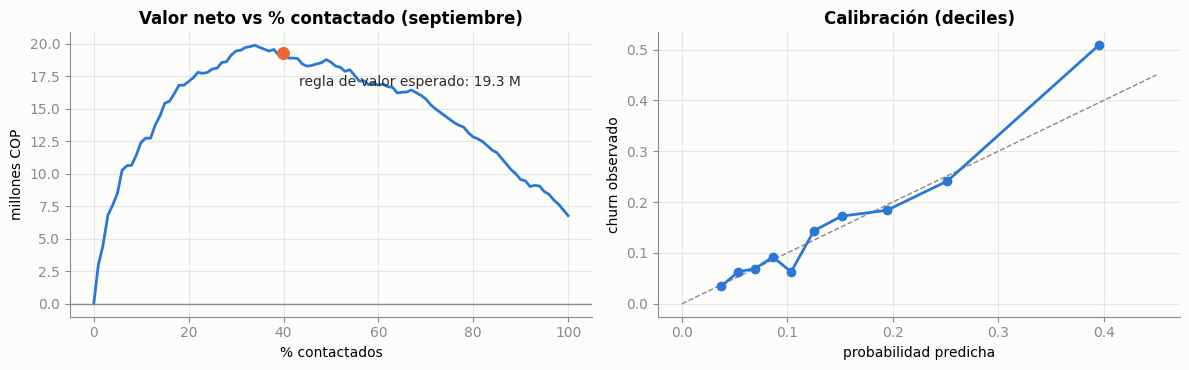

{'roc_auc': np.float64(0.7502), 'pr_auc': np.float64(0.4339), 'brier': np.float64(0.1137), 'valor_neto': 19276880.0, 'pct_del_maximo': 0.4431, 'contactados': 694}


In [13]:
tr = F[F.fecha_corte.isin(pd.to_datetime(m.CORTES_TRAIN))].reset_index(drop=True)
va = F[F.fecha_corte == pd.Timestamp(m.CORTE_VALID)].reset_index(drop=True)
ens = m.entrenar(tr)
p_va = ens.predict_proba(va[m.X_COLS])[:, 1]; y_va = va.churn_90d.astype(int)
r = m.metricas(y_va, p_va, va.precio_plan)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cv = negocio.curva_valor(y_va, p_va, va.precio_plan)
axes[0].plot(cv.pct_contactados * 100, cv.valor_neto / 1e6, color=AZUL); axes[0].axhline(0, color=TENUE, lw=1)
axes[0].scatter([r["pct_contactados"] * 100], [r["valor_neto"] / 1e6], color=NARANJA, s=70, zorder=3)
axes[0].annotate(f"regla de valor esperado: {r['valor_neto']/1e6:.1f} M", (r["pct_contactados"] * 100, r["valor_neto"] / 1e6),
                 xytext=(12, -24), textcoords="offset points", color=TINTA)
axes[0].set_title("Valor neto vs % contactado (septiembre)"); axes[0].set_xlabel("% contactados"); axes[0].set_ylabel("millones COP")
cal = pd.DataFrame({"p": p_va, "y": y_va}).groupby(pd.qcut(p_va, 10, duplicates="drop"), observed=True).mean()
axes[1].plot([0, 0.45], [0, 0.45], color=TENUE, lw=1, ls="--"); axes[1].plot(cal.p, cal.y, color=AZUL, marker="o")
axes[1].set_title("Calibración (deciles)"); axes[1].set_xlabel("probabilidad predicha"); axes[1].set_ylabel("churn observado")
plt.tight_layout(); plt.show()
print({k: round(v, 4) for k, v in r.items() if k in ["roc_auc", "pr_auc", "brier", "valor_neto", "pct_del_maximo", "contactados"]})

In [14]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
pi = permutation_importance(ens, va[m.X_COLS], y_va, scoring=lambda e, X, y: average_precision_score(y, e.predict_proba(X)[:, 1]),
                            n_repeats=10, random_state=0)
imp = pd.DataFrame({"variable": m.X_COLS, "importancia": pi.importances_mean}).sort_values("importancia", ascending=False).head(12)
l1 = ens.modelos["02_logistica_l1"].calibrated_classifiers_[0].estimator
coef = pd.Series(l1[-1].coef_[0], index=[n.split("__", 1)[1] for n in l1[:-1].get_feature_names_out()])
imp["efecto_logistica (+ = más riesgo)"] = imp.variable.map(lambda v: coef.get(v, np.nan)).round(3)
imp.round(4)

,variable,importancia,efecto_logistica (+ = más riesgo)
8,contacto_retencion_previo,0.0685,0.261
30,logins_30d,0.0503,-0.447
35,crash_30d,0.0443,0.030
18,tickets_cancelar_30d,0.0388,0.319
33,uso_30d,0.0298,-0.343
44,plataforma_principal,0.0138,NaN
34,duracion_uso_30d,0.0127,-0.111
37,dias_desde_ultimo_evento,0.0048,0.129
0,antiguedad_dias,0.0042,-0.020
29,csat_prom_90d,0.0028,-0.024


**Por qué se van (según el modelo):** contacto de retención previo (es reactivo: el cliente ya pidió irse), poco uso y
pocos logins en 30 días, cierres de la app (`CRASH_ON_START`) y la intención de cancelar detectada en tickets.

In [15]:
p = LAKE / "_calidad" / "experimento_cortes.csv"
res_c, deltas_c, _ = experimento_cortes.run(LAKE)
deltas_c.round(4)

,variante,modelo,delta_auc_vs_A,ic95_bajo,ic95_alto
0,B_mensual_2025,logistica,0.0042,-0.0007,0.0089
1,B_mensual_2025,lightgbm,0.0096,-0.0068,0.0255
2,C_mensual_desde_2024,logistica,-0.0115,-0.0262,0.0041
3,C_mensual_desde_2024,lightgbm,-0.0172,-0.0423,0.0087
4,D_mensual_desde_2023,logistica,-0.0144,-0.0290,0.0016
5,D_mensual_desde_2023,lightgbm,-0.0139,-0.0374,0.0115


**Anotación — cortes adicionales:** generar cortes mensuales (la regla de etiqueta está verificada) no mejora de forma
significativa (2025: +0,004 a +0,010 AUC con IC 95 % que incluye 0) y agregar 2023–2024 empeora (otro régimen: sin logs
de app, precio anterior). Se usan los 3 cortes oficiales.

## 4. Seguimiento de experimentos con MLflow (local, sin servidor)

In [16]:
import mlflow
URI = f"sqlite:///{(RAIZ / 'mlflow.db').as_posix()}"
runs = m.registrar_mlflow(LAKE, uri=URI, experimento="conecta_churn_solucion", resultados=resultados)
runs[["tags.mlflow.runName", "metrics.pct_max_prom", "metrics.pct_del_maximo_06", "metrics.pct_del_maximo_09",
      "metrics.valor_neto_09", "metrics.roc_auc_09", "metrics.pr_auc_09", "metrics.brier_09"]].round(4)

,tags.mlflow.runName,metrics.pct_max_prom,metrics.pct_del_maximo_06,metrics.pct_del_maximo_09,metrics.valor_neto_09,metrics.roc_auc_09,metrics.pr_auc_09,metrics.brier_09
0,20_ensamble_elegido_l1_rf_50_50,0.3669,0.2906,0.4431,19276880.0,0.7502,0.4339,0.1137
1,02_logistica_l1,0.3438,0.2909,0.3967,17256000.0,0.7362,0.4187,0.1143
2,01_logistica,0.3431,0.2705,0.4157,18084040.0,0.7284,0.4064,0.1154
3,04_random_forest,0.3395,0.2478,0.4312,18758640.0,0.7432,0.3754,0.1184
4,13_logistica_peso_valor,0.3268,0.2439,0.4098,17824480.0,0.7154,0.3753,0.1217
5,12_ensamble_log_rf_lgbm,0.3256,0.2259,0.4254,18504520.0,0.7436,0.4109,0.1147
6,05_extra_trees,0.3207,0.2383,0.4032,17537840.0,0.7243,0.3778,0.1189
7,14_lightgbm_peso_valor,0.3035,0.2198,0.3872,16843560.0,0.7030,0.3465,0.1229
8,06_hist_gradient_boosting,0.2977,0.2117,0.3837,16689760.0,0.7001,0.3535,0.1224
9,08_knn,0.2927,0.2442,0.3413,14846320.0,0.6772,0.2774,0.1267


16 corridas: la línea base (tasa histórica por plan × segmento), 14 modelos y el ensamble elegido, cada una con
parámetros, métricas de ambos pliegues y el modelo como artefacto. **Corrida elegida: `20_ensamble_elegido_l1_rf_50_50`**:
mayor % del valor máximo promedio, mejor que sus componentes en ambos pliegues y calibración tan buena como la de la logística.
La línea base confirma que el modelo aporta (≈2,5× más valor en septiembre). La carpeta `mlruns`/`mlflow.db` no se sube al repositorio.

## 5. Decisión de negocio: a quién contactar

Valor de contactar a un cliente con los supuestos del enunciado:

| | Iba a cancelar (p) | No iba a cancelar (1 − p) |
|---|---|---|
| Contactar | 0,40 × 12 × precio vigente − 25.000 | −25.000 |
| No contactar | 0 | 0 |

**Contactar si p > 25.000 / (4,8 × precio)**: Básico 0,218 · Estándar 0,149 · Premium 0,104 · Familiar 0,087.
Los planes caros justifican contactar con menos riesgo porque retenerlos vale más.

**Política adicional (decisión de negocio):** no se vuelve a contactar a quien ya recibió una oferta de retención
(el 94 % de los contactados históricos canceló igual). Bajo los supuestos del enunciado esto **cuesta** valor; se mide
abajo y es reversible (`config.EXCLUIR_CONTACTADOS_PREVIOS`).

In [17]:
filas = []
for cortes_tr, cva in m.PLIEGUES:
    t_ = F[F.fecha_corte.isin(pd.to_datetime(cortes_tr))].reset_index(drop=True)
    v_ = F[F.fecha_corte == pd.Timestamp(cva)].reset_index(drop=True)
    p_ = m.entrenar(t_).predict_proba(v_[m.X_COLS])[:, 1]
    y_, pr_ = v_.churn_90d.astype(int), v_.precio_plan
    ex = v_.contacto_retencion_previo.to_numpy() == 1
    filas.append({"valida": cva, "valor_sin_politica_M": negocio.valor_realizado(y_, negocio.decidir(p_, pr_), pr_) / 1e6,
                  "valor_con_politica_M": negocio.valor_realizado(y_, negocio.decidir(p_, pr_, ex), pr_) / 1e6,
                  "maximo_posible_M": negocio.valor_realizado(y_, y_, pr_) / 1e6})
pd.DataFrame(filas).round(2)

,valida,valor_sin_politica_M,valor_con_politica_M,maximo_posible_M
0,2025-06-30,10.22,8.13,35.15
1,2025-09-30,19.28,16.57,43.50


In [18]:
trf = F[F.conjunto == "entrenamiento"].reset_index(drop=True)
sc = F[F.conjunto == "puntuar"].reset_index(drop=True)
final = m.entrenar(trf)                                   # 3 cortes
pred = m.predecir(final, sc)
m.validar_predicciones(pred, io.read(LAKE, "silver", "clientes_a_puntuar"))
pred[["cliente_id", "probabilidad", "contactar"]].sort_values("cliente_id").to_csv(RAIZ / "predicciones.csv", index=False)
k = pred.contactar == 1
print(f"predicciones.csv: {len(pred)} clientes · contactar {k.sum()} ({k.mean():.0%}) · "
      f"excluidos por contacto previo: {((pred.excluido_por_contacto_previo == 1) & (pred.valor_esperado_contacto > 0)).sum()}")
print(f"Costo de la campaña: {k.sum() * config.COSTO_CONTACTO / 1e6:.1f} M COP · "
      f"valor esperado neto según el modelo: {pred.loc[k, 'valor_esperado_contacto'].sum() / 1e6:.1f} M COP")
pred.groupby("plan").agg(clientes=("cliente_id", "size"), prob_media=("probabilidad", "mean"), contactar=("contactar", "sum"),
                         umbral=("precio_plan", lambda s: negocio.umbral(s.iloc[0]))).round(3)

predicciones.csv: 1558 clientes · contactar 522 (34%) · excluidos por contacto previo: 46
Costo de la campaña: 13.1 M COP · valor esperado neto según el modelo: 12.4 M COP


,clientes,prob_media,contactar,umbral
plan,,,,
Basico,449,0.154,83,0.218
Estandar,524,0.145,157,0.149
Familiar,257,0.158,146,0.087
Premium,328,0.143,136,0.104


**Valor estimado de la decisión.** El modelo espera ~12 M COP netos sobre ~13 M de costo de contactos. Validado en
septiembre la misma estrategia (con la política) dejó ~16 M COP, frente a 6,8 M de contactar a todos. Como el churn
viene subiendo y el modelo tiende a subestimar en los deciles altos, el valor real podría ser mayor que el esperado.

In [19]:
filas = []
for exito in [0.3, 0.4, 0.5]:
    for costo in [20_000, 25_000, 35_000]:
        ve = pred.probabilidad * exito * config.MESES_VALOR_RETENCION * pred.precio_plan - costo
        kk = (ve > 0) & (pred.excluido_por_contacto_previo == 0)
        filas.append({"tasa_exito": exito, "costo_contacto": costo, "contactar": int(kk.sum()),
                      "valor_esperado_M": ve[kk].sum() / 1e6})
pd.DataFrame(filas).pivot(index="tasa_exito", columns="costo_contacto", values="contactar")

costo_contacto,20000,25000,35000
tasa_exito,,,
0.3,479,363,194
0.4,666,522,335
0.5,840,666,446


## 6. Hallazgo abierto: la actualización Android 5.4.0 está expulsando clientes

Nadie preguntó por la app, pero los datos de tres sistemas distintos (logs, tickets y CRM) cuentan la misma historia.

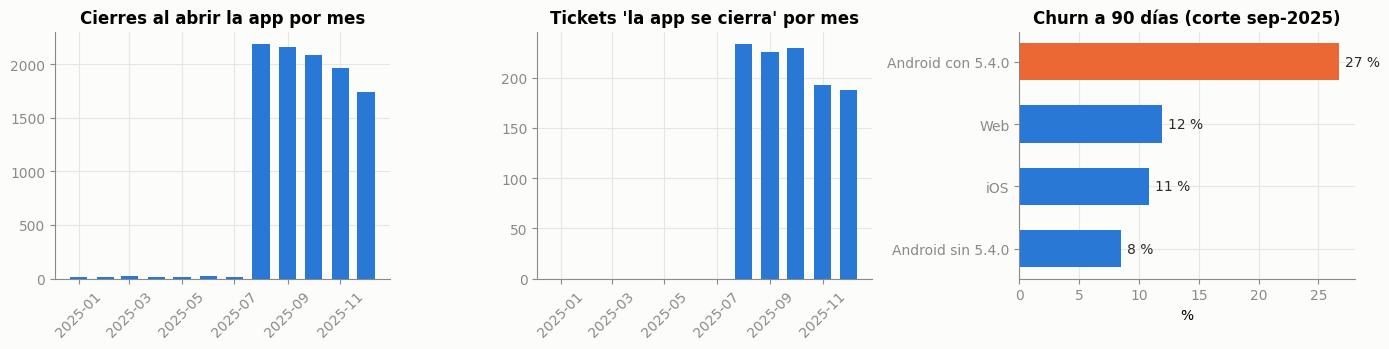

,clientes,tasa_churn
grupo,,
Android sin 5.4.0,353,0.085
iOS,637,0.108
Web,176,0.119
Android con 5.4.0,577,0.267


Churn por plataforma y corte:


fecha_corte,2025-03-31,2025-06-30,2025-09-30
plataforma_principal,,,
android,0.104,0.183,0.198
ios,0.092,0.087,0.108
web,0.135,0.076,0.119


Participación de 'problemas_tecnicos' en las cancelaciones por trimestre:


,motivo_cancelacion
fecha_fin,
2025Q1,0.15
2025Q2,0.11
2025Q3,0.30
2025Q4,0.33


In [20]:
ev = io.read(LAKE, "silver", "eventos")
meses = pd.period_range("2025-01", "2025-12", freq="M")
crash = ev[ev.codigo_error == "CRASH_ON_START"].groupby(ev.ts.dt.to_period("M")).size().reindex(meses, fill_value=0)
app_tk = tk[tk.categoria == "app_se_cierra"].groupby(tk.creado_en.dt.to_period("M")).size().reindex(meses, fill_value=0)
s9 = F[F.fecha_corte == "2025-09-30"].copy()
s9["grupo"] = np.where(s9.usa_version_540 == 1, "Android con 5.4.0",
                np.where(s9.plataforma_principal == "android", "Android sin 5.4.0", s9.plataforma_principal.map({"ios": "iOS", "web": "Web"})))
g = s9.groupby("grupo").churn_90d.agg(clientes="size", tasa_churn="mean").sort_values("tasa_churn")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].bar(meses.to_timestamp(), crash.values, width=20, color=AZUL); axes[0].set_title("Cierres al abrir la app por mes")
axes[1].bar(meses.to_timestamp(), app_tk.values, width=20, color=AZUL); axes[1].set_title("Tickets 'la app se cierra' por mes")
for a in axes[:2]: a.tick_params(axis="x", rotation=45)
axes[2].barh(g.index, g.tasa_churn * 100, color=[NARANJA if "con 5.4.0" in i else AZUL for i in g.index], height=0.6)
for i, v in enumerate(g.tasa_churn * 100): axes[2].text(v + 0.5, i, f"{v:.0f} %", va="center", color=TINTA)
axes[2].set_title("Churn a 90 días (corte sep-2025)"); axes[2].set_xlabel("%")
plt.tight_layout(); plt.show()
display(g.round(3))
print("Churn por plataforma y corte:"); display(F[F.conjunto == "entrenamiento"].pivot_table(index="plataforma_principal", columns="fecha_corte", values="churn_90d").round(3))
c = su[su.fin_es_churn & (su.fecha_fin >= "2025-01-01")]
print("Participación de 'problemas_tecnicos' en las cancelaciones por trimestre:")
display((c.motivo_cancelacion == "problemas_tecnicos").groupby(c.fecha_fin.dt.to_period("Q")).mean().round(2))

In [21]:
exceso = (g.loc["Android con 5.4.0", "tasa_churn"] - g.loc["Android sin 5.4.0", "tasa_churn"]) * g.loc["Android con 5.4.0", "clientes"]
precio_medio = s9.loc[s9.usa_version_540 == 1, "precio_plan"].mean()
print(f"Cancelaciones en exceso en un trimestre: ~{exceso:.0f} clientes → ~{exceso * 12 * precio_medio / 1e6:.0f} M COP de ingresos anuales en riesgo")
print(f"Clientes activos hoy con la versión 5.4.0: {int(sc.usa_version_540.sum())} de {len(sc)}")

Cancelaciones en exceso en un trimestre: ~105 clientes → ~49 M COP de ingresos anuales en riesgo
Clientes activos hoy con la versión 5.4.0: 458 de 1558


**Evidencia.** La versión 5.4.0 sale el 1-ago-2025 solo en Android. Desde ese mes los cierres al abrir la app pasan de
~15 a ~2.000 por mes, aparece la categoría de ticket "la app se cierra" (con quejas sarcásticas que «felicitan» por la nueva versión mientras reclaman el fallo), el churn de Android se duplica y los "problemas técnicos" pasan a
ser un tercio de los motivos de cancelación. Quien usa la 5.4.0 cancela ~3 veces más que un usuario Android sin ella.

**Acción propuesta.**
1. Revertir o corregir la versión 5.4.0 de inmediato (es una causa controlable, a diferencia del precio o la competencia).
2. Contactar de forma proactiva a los usuarios activos de la 5.4.0 con el arreglo y una compensación, priorizando a los
   que la lista de riesgo ya marca.
3. Agregar una alarma de calidad por versión (tasa de cierres por versión/plataforma) antes de liberar a todos los usuarios.

**Otros hallazgos (secundarios).** (a) La retención es reactiva: el contacto llega 3–19 días antes de que el cliente se
vaya y el 94 % cancela igual → usar la lista de riesgo para contactar **antes** de que pidan cancelar.
(b) El Básico subió 20 % en abril-2025 sin aviso según los tickets, que reclaman el aumento sin aviso previo; su churn pasó de
11 % a 19 %.

## 7. Llevarlo a producción

- **Frecuencia: reentrenar es lo que más importa; puntuar más seguido ayuda poco por sí solo.**
  - *Reentrenar* cada trimestre, cuando cierran las etiquetas a 90 días, con una ventana móvil de datos recientes,
    y antes si se dispara una alarma (tasa real vs. predicha, calibración por plan, corrección de la 5.4.0, cambio
    de precios). Evidencia: la tasa base sube cada trimestre (10 % → 16 %) y agregar cortes de 2023–2024 empeoró
    el modelo (otro régimen).
  - *Puntuar* cada mes con el pipeline `bronze → silver → gold` para mantener la lista al día (clientes nuevos,
    fallos recientes). Simulación con el mismo modelo (`conecta/experimento_frecuencia.py`): volver a puntuar el
    31-oct y el 30-nov agrega 331 llamadas y casi nada de valor (+0,8 M y −1,0 M; las rondas tardías se observan
    menos de 90 días). De los 116 clientes que cancelan oct–dic sin ser marcados el 30-sep, el 41 % solo da la
    señal después (ticket pidiendo cancelar), y quien pide cancelar se va en 1–14 días: es la misma razón por la
    que hoy la llamada de retención llega 3–19 días antes de la baja.
  - *Conclusión:* puntuar más seguido con señales tardías solo hace llamar tarde más seguido. Para llamar **antes**
    hace falta un modelo de alerta temprana basado en señales anticipadas (caída de uso, fallos, quejas
    recurrentes), probado sin las variables tardías (contacto previo, ticket de cancelación). Cada corrida en MLflow con versión de
  datos (SHA-256 de la ingesta) y del modelo; el reemplazo exige superar al modelo vigente en valor neto fuera de tiempo.
- **Monitoreo del negocio.** Valor neto realizado de los contactos (con grupo de control aleatorio pequeño, para medir
  el efecto real de la oferta en vez de suponer el 40 %), tasa de aceptación y churn de contactados vs no contactados.
- **Monitoreo del modelo.** Calibración por plan (probabilidad media vs churn observado a 90 días), PR-AUC, deriva de las
  variables (PSI) y de la tasa base de churn, que hoy sube cada trimestre.
- **Calidad de datos.** Los checks del pipeline ya detienen la corrida si algo se rompe; vigilar en especial cambios de
  esquema (como el de tickets en jun-2025), facturas recargadas, IDs que no cruzan y textos de tickets fuera del set de
  referencia del NLP.
- **Qué me haría desconfiar.** Que la tasa real se separe de la predicha (prior shift), un salto en una variable dominante
  (contactos de retención, logins o cierres de la app: si se arregla la 5.4.0 el modelo sobreestimará el riesgo de
  Android), cambios de precios o planes, una nueva plataforma o versión, y que la política de contacto cambie quién llega
  a la etiqueta (el propio modelo influye en los datos futuros: por eso el grupo de control).

## 8. Limitaciones y riesgos

- Tres cortes de entrenamiento y un churn creciente: la validación depende de pocos meses y el modelo puede subestimar
  el riesgo de enero–marzo 2026.
- El 40 % de éxito de la oferta es un supuesto; sin grupo de control no se puede verificar.
- La variable más predictiva (contacto de retención previo) refleja una práctica reactiva; si el equipo cambia su forma
  de contactar, el modelo debe reentrenarse.
- El NLP es exacto en las 38 plantillas actuales, pero generaliza a ~79 % con textos nuevos.
- Los eventos solo cubren 2025: no hay historia de uso para los cortes anteriores.

Uso de IA y tiempo invertido: ver `BITACORA_IA.md`. Decisiones con alternativas descartadas: `DECISIONES.md`.